# Isoko Price Check: predicting farm produce prices in Rwanda

**Author:** Methode Duhujubumwe

**Mission.** I want to empower rural farmers in Rwanda with real time information on prices, weather and market opportunities, through simple apps that run on the phones they already have.

**Use case.** A farmer, a cooperative leader or an extension officer enters a market, a product, a month and a year. The model returns the expected market price in RWF per unit. The farmer uses it before harvest or before going to market, to judge if a trader's offer is fair and to compare markets before deciding where to sell.

**Target.** `price`, the market price of one unit (kg, litre or piece) of a product in Rwandan francs. It is a continuous number, so this is a regression problem.

## 1. Data source

The data is the **WFP Rwanda Food Prices** dataset, published by the World Food Programme on the Humanitarian Data Exchange (HDX): https://data.humdata.org/dataset/wfp-food-prices-for-rwanda

How the data was collected: WFP compiles monthly market prices from its own Rwanda market monitoring (field price collection in markets and the mobile phone surveys called mVAM), and from MINAGRI and FAO price series (GIEWS / FPMA). Each row is one product, at one market, in one month. The file I use runs from January 2000 to August 2026 and has 16 columns: 11 text columns (province, district, market, product, category, unit, price type and more) and 5 numeric columns (latitude, longitude, ids, price in RWF and price in USD).

In [1]:
import io
import json
import warnings
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import MaxNLocator
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore", category=RuntimeWarning)
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

API_DIR = Path("../API")
(API_DIR / "data").mkdir(parents=True, exist_ok=True)

In [2]:
raw = pd.read_csv("wfp_food_prices_rwa.csv")
print("Rows:", raw.shape[0], "| Columns:", raw.shape[1])
raw.head()

Rows: 157692 | Columns: 16


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2000-01-15,Kigali City,Nyarugenge,Kigali,1076,-1.95,30.06,cereals and tubers,Maize,51,KG,actual,Wholesale,RWF,206.11,0.60
1,2000-01-15,Kigali City,Nyarugenge,Kigali,1076,-1.95,30.06,pulses and nuts,Beans,50,KG,actual,Wholesale,RWF,108.02,0.32
2,2000-02-15,Kigali City,Nyarugenge,Kigali,1076,-1.95,30.06,cereals and tubers,Maize,51,KG,actual,Wholesale,RWF,152.66,0.45
3,2000-02-15,Kigali City,Nyarugenge,Kigali,1076,-1.95,30.06,pulses and nuts,Beans,50,KG,actual,Wholesale,RWF,110.22,0.32
4,2000-03-15,Kigali City,Nyarugenge,Kigali,1076,-1.95,30.06,cereals and tubers,Maize,51,KG,actual,Wholesale,RWF,159.27,0.47


In [3]:
summary = pd.DataFrame({
    "type": raw.dtypes.astype(str),
    "unique values": raw.nunique(),
    "missing values": raw.isna().sum(),
    "example": raw.iloc[0],
})
summary

,type,unique values,missing values,example
date,str,295,0,2000-01-15
admin1,str,5,0,Kigali City
admin2,str,29,0,Nyarugenge
market,str,109,0,Kigali
market_id,int64,109,0,1076
latitude,float64,64,0,-1.95
longitude,float64,72,0,30.06
category,str,8,0,cereals and tubers
commodity,str,65,0,Maize
commodity_id,int64,65,0,51


## 2. Data quality checks

Before plotting anything I check for missing values, duplicate rows and the time coverage.

In [4]:
raw["date"] = pd.to_datetime(raw["date"])
raw["year"] = raw["date"].dt.year
raw["month"] = raw["date"].dt.month

print("Missing values in the whole file:", int(raw.isna().sum().sum()))
print("Fully duplicated rows:", int(raw.duplicated().sum()))
key = ["date", "market", "commodity", "pricetype", "unit"]
print("Duplicated (date, market, product, price type, unit):", int(raw.duplicated(subset=key).sum()))
print("\nRows per year:")
print(raw.groupby("year").size().to_string())

Missing values in the whole file: 0


Fully duplicated rows: 0
Duplicated (date, market, product, price type, unit): 0

Rows per year:
year
2000       24
2001       16
2002        4
2003       24
2004       12
2005       10
2006       36
2007       36
2008     4159
2009     4194
2010     5190
2011    11141
2012    18877
2013    23015
2014    24835
2015    27264
2016      610
2017     2435
2018     4366
2019     4775
2020     4711
2021     3930
2022     3209
2023     3738
2024     4206
2025     4232
2026     2643


The file has **no missing values** and **no duplicates**, so I do not drop any row for those reasons. A new CSV sent to the API later could have gaps, so the model pipeline still has imputers inside it: a missing number is filled with the training median and a missing text value with the most common training value. This way a row with one blank cell is kept, not thrown away.

Coverage: before 2008 there are only 161 rows in total, almost all from Kigali. From 2008 the data covers markets in all five provinces. I keep **2008 onwards** so the model learns from the period that actually represents the whole country.

In [5]:
df = raw[raw["year"] >= 2008].copy()

# Charcoal is the only non-food item. It is sold by the sack and it is not farm produce, so it is outside my use case.
print("Charcoal rows removed:", int((df["category"] == "non-food").sum()))
df = df[df["category"] != "non-food"]
df = df[df["price"] > 0]

# The newest three months are kept aside. They play the role of "new data that arrives later" for the /retrain endpoint.
NEW_DATA_START = pd.Timestamp("2026-06-01")
new_data = raw[(raw["date"] >= NEW_DATA_START) & (raw["category"] != "non-food")].drop(columns=["year", "month"])
new_data.assign(date=new_data["date"].dt.strftime("%Y-%m-%d")).to_csv(API_DIR / "sample_new_data.csv", index=False)
df = df[df["date"] < NEW_DATA_START]
print("Rows kept for modelling:", len(df), "| Rows saved as new data for retraining:", len(new_data))

Charcoal rows removed: 2799
Rows kept for modelling: 153836 | Rows saved as new data for retraining: 895


### Removing impossible prices

Some prices are far from every other price of the same product. A row is removed only if its price is more than **4 times above or below the median price of the same product, price type and year**. Comparing within the same year matters. Beef went from a median of 2,750 RWF per kg in 2021 to 7,000 in 2026. In my first try I compared each price with the whole 2008 to 2026 history of the product, and that rule removed about 150 real beef prices from 2025 and 2026, which are the most useful rows for a farmer today.

In [6]:
df["log_price"] = np.log1p(df["price"])
OUTLIER_FACTOR = 4
yearly_median = df.groupby(["commodity", "pricetype", "year"])["price"].transform("median")
ratio = df["price"] / yearly_median
is_outlier = (ratio > OUTLIER_FACTOR) | (ratio < 1 / OUTLIER_FACTOR)
print(f"Rows flagged: {int(is_outlier.sum())} of {len(df)} ({is_outlier.mean():.2%})")
print(df.loc[is_outlier, ["date", "market", "commodity", "pricetype", "price"]].assign(
    times_the_median=ratio[is_outlier].round(2)).head(8).to_string())
df = df[~is_outlier].copy()
print("\nRows after cleaning:", len(df))

Rows flagged: 206 of 153836 (0.13%)
            date       market         commodity pricetype     price  times_the_median
973   2008-03-15   Nyakarambi         Eggplants    Retail     32.50              0.24
14246 2011-01-15     Kibirizi          Zucchini    Retail     56.67              0.24
14618 2011-01-15  Congo - Nil             Guava    Retail     35.00              0.19
14625 2011-01-15  Congo - Nil          Zucchini    Retail     41.75              0.18
14717 2011-02-15    Kabarondo  Livestock (Goat)    Retail  90250.00              4.72
15165 2011-02-15     Kibirizi          Zucchini    Retail     47.00              0.20
15482 2011-02-15      Birambo          Zucchini    Retail     39.67              0.17
15508 2011-02-15  Congo - Nil          Zucchini    Retail     46.00              0.19

Rows after cleaning: 153630


## 3. Visualisations that guide the modelling

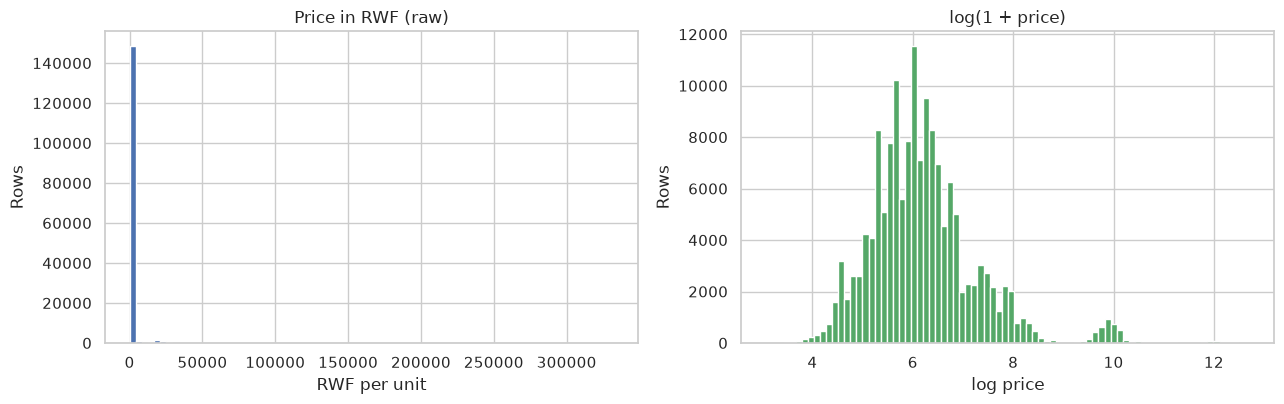

Skewness raw price: 19.18 | skewness log price: 1.33


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].hist(df["price"], bins=80, color="#4C72B0")
axes[0].set(title="Price in RWF (raw)", xlabel="RWF per unit", ylabel="Rows")
axes[1].hist(df["log_price"], bins=80, color="#55A868")
axes[1].set(title="log(1 + price)", xlabel="log price", ylabel="Rows")
plt.tight_layout()
plt.show()
print("Skewness raw price:", round(df["price"].skew(), 2), "| skewness log price:", round(df["log_price"].skew(), 2))

**What it shows.** Raw prices are extremely skewed: most rows cost a few hundred RWF per kg, while live animals cost tens of thousands per head, so the histogram is one tall bar near zero. After taking the log, the distribution is spread out and close to symmetric.

**What I decided.** I train every model on `log(1 + price)` and convert back with `exp(x) - 1` when I return a price. Without this, the squared error would be ruled by a few cattle and goat prices, and the model would care little about the beans, maize and potato prices that most farmers need.

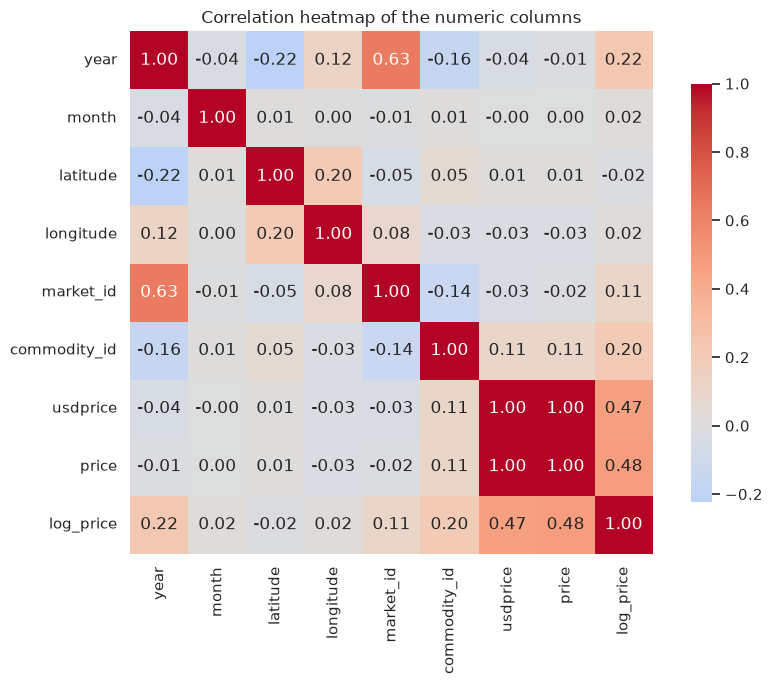

price           0.480
usdprice        0.470
year            0.221
commodity_id    0.200
market_id       0.112
longitude       0.022
latitude       -0.021
month           0.018


In [8]:
numeric_cols = ["year", "month", "latitude", "longitude", "market_id", "commodity_id", "usdprice", "price", "log_price"]
corr = df[numeric_cols].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": 0.8})
plt.title("Correlation heatmap of the numeric columns")
plt.tight_layout()
plt.show()
print(corr["log_price"].drop(["log_price"]).sort_values(key=abs, ascending=False).round(3).to_string())

**What it shows.** `usdprice` moves almost one to one with `price`, because it is the same price converted to dollars. `market_id` and `commodity_id` are just code numbers, and latitude and longitude have a weak link with the log price. `year` has the strongest link of the real inputs, because prices rise with inflation over time. `month` alone is close to zero, but it can still matter inside each crop (harvest seasons).

**What I decided.** I drop `usdprice`, because it is the target in another currency and would leak the answer. I drop the two id columns, because their numbers have no meaning. I keep `year` and `month` as numeric inputs. I do not keep latitude and longitude, because the market name already fixes the exact location (each market has one pair of coordinates).

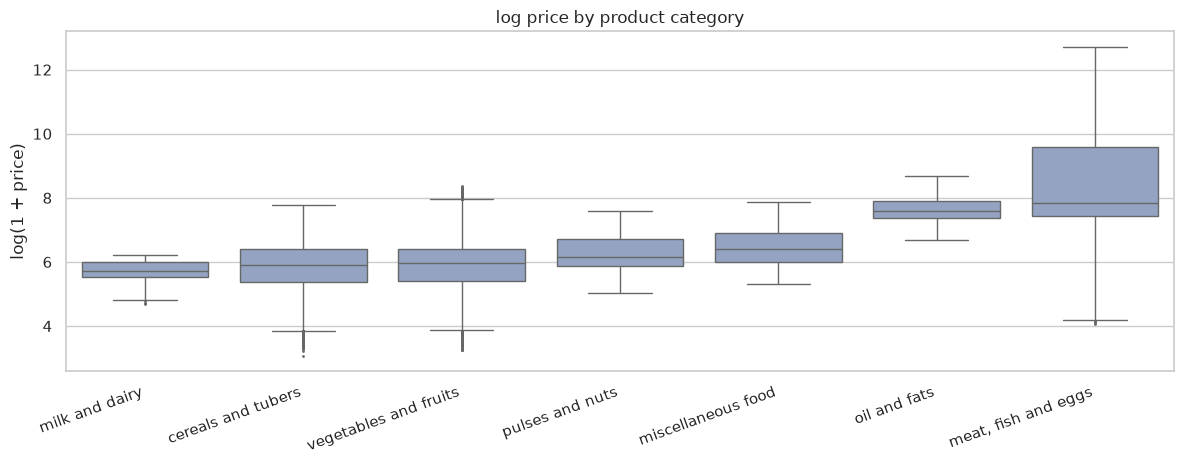

Share of log price variance explained by each text column alone:
commodity    0.893
category     0.374
unit         0.151
market       0.028
priceflag    0.018
admin2       0.014
admin1       0.001
pricetype    0.000


In [9]:
order = df.groupby("category")["log_price"].median().sort_values().index
plt.figure(figsize=(12, 4.8))
sns.boxplot(data=df, x="category", y="log_price", order=order, color="#8DA0CB", fliersize=1)
plt.xticks(rotation=20, ha="right")
plt.title("log price by product category")
plt.xlabel("")
plt.ylabel("log(1 + price)")
plt.tight_layout()
plt.show()


def correlation_ratio(categories, values):
    # Share of the variance in values that is explained by the category groups (eta squared).
    frame = pd.DataFrame({"c": categories, "v": values})
    overall = frame["v"].mean()
    between = frame.groupby("c")["v"].agg(["count", "mean"])
    ss_between = (between["count"] * (between["mean"] - overall) ** 2).sum()
    ss_total = ((frame["v"] - overall) ** 2).sum()
    return ss_between / ss_total


text_cols = ["commodity", "category", "unit", "market", "admin2", "admin1", "pricetype", "priceflag"]
eta = pd.Series({c: correlation_ratio(df[c], df["log_price"]) for c in text_cols}).sort_values(ascending=False)
print("Share of log price variance explained by each text column alone:")
print(eta.round(3).to_string())

**What it shows.** The kind of product decides most of the price. Meat and live animals sit far above vegetables, cereals and tubers. The table confirms it: the product (`commodity`) alone explains most of the variance in the log price, while the market, district and province alone explain much less.

**What I decided.** `commodity` is the most important input. `category` and `unit` are fully decided by the product (every product has exactly one category and one unit in this file), so I drop them to avoid repeating the same information. The same holds for location: each market belongs to one district and one province, so I keep `market` and drop `admin2` and `admin1`.

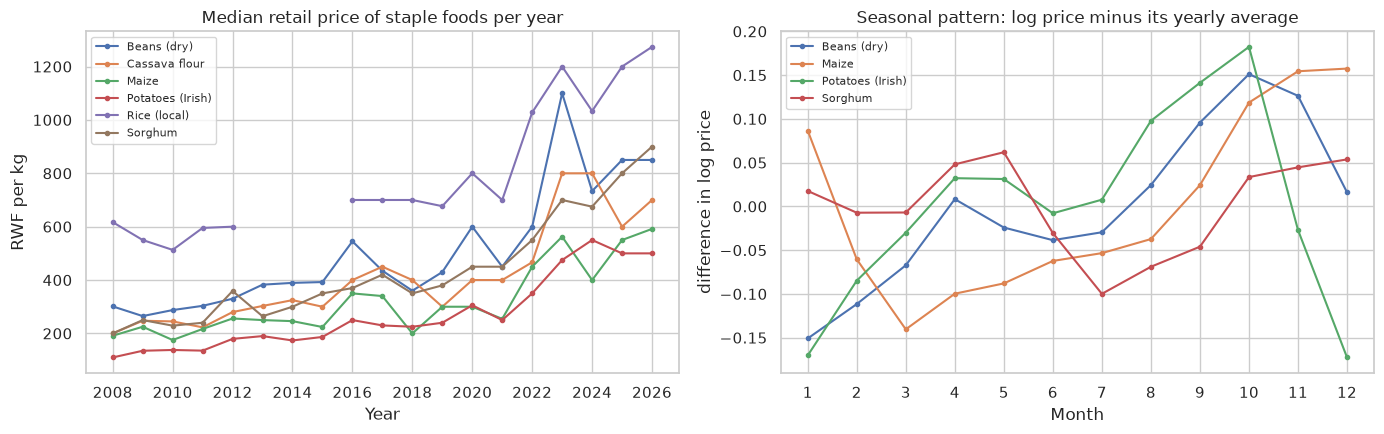

In [10]:
staples = ["Beans (dry)", "Maize", "Potatoes (Irish)", "Cassava flour", "Sorghum", "Rice (local)"]
yearly = (df[df["commodity"].isin(staples) & (df["pricetype"] == "Retail")]
          .groupby(["year", "commodity"])["price"].median().unstack())
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
yearly.plot(ax=axes[0], marker="o", markersize=3)
axes[0].set(title="Median retail price of staple foods per year", xlabel="Year", ylabel="RWF per kg")
axes[0].legend(fontsize=8)
axes[0].xaxis.set_major_locator(MaxNLocator(integer=True))
seasonal = (df[df["commodity"].isin(["Beans (dry)", "Maize", "Potatoes (Irish)", "Sorghum"])]
            .groupby(["month", "commodity"])["log_price"].mean().unstack())
(seasonal - seasonal.mean()).plot(ax=axes[1], marker="o", markersize=3)
axes[1].set(title="Seasonal pattern: log price minus its yearly average", xlabel="Month", ylabel="difference in log price")
axes[1].legend(fontsize=8)
axes[1].set_xticks(range(1, 13))
plt.tight_layout()
plt.show()

**What it shows.** Prices of all staples rose over time, but not at the same speed: some crops jumped much more after 2022 than others. The right plot shows that each crop has its own seasonal cycle, with prices low after harvest and high in the lean months, and the peaks are not in the same month for every crop.

**What I decided.** The effect of `year` and `month` depends on the product. A straight line model gives one slope for year and one for month for all products, so I expect it to miss these patterns. Tree models can split on product first and then on time, so I expect the decision tree and the random forest to do better. I keep `year` and `month` as inputs for this reason.

## 4. Feature engineering

| Column | Kept? | Reason |
|---|---|---|
| `date` | replaced | Turned into `year` and `month`, which a farmer can type and a model can use. |
| `market` | kept | Location of the sale. It fixes district, province, latitude and longitude. |
| `commodity` | kept | The strongest input by far. |
| `pricetype` | kept, renamed `price_type` | Retail or Wholesale. Wholesale prices are lower for the same crop. |
| `admin1`, `admin2`, `latitude`, `longitude` | dropped | Fully decided by `market`, so they repeat information. |
| `category`, `unit` | dropped | Fully decided by `commodity`. The API still returns the unit with each prediction. |
| `market_id`, `commodity_id` | dropped | Code numbers with no meaning as quantities. |
| `currency` | dropped | Always RWF. |
| `usdprice` | dropped | The target in dollars, it would leak the answer. |
| `priceflag` | dropped | Tells how WFP built the number (actual or averaged). A farmer cannot know it when asking for a price. |

Final inputs: **`year`, `month`, `market`, `commodity`, `price_type`** (2 numeric and 3 categorical). Target: **`log(1 + price)`**.

In [11]:
data = df.rename(columns={"pricetype": "price_type"})
FEATURES = ["year", "month", "market", "commodity", "price_type"]
NUMERIC = ["year", "month"]
CATEGORICAL = ["market", "commodity", "price_type"]
TARGET = "price"

X = data[FEATURES]
y_price = data[TARGET]
y = np.log1p(y_price)
print(X.shape)
X.head()

(153630, 5)


,year,month,market,commodity,price_type
162,2008,1,Ruhuha,Cassava,Retail
163,2008,1,Ruhuha,Cassava flour,Retail
164,2008,1,Ruhuha,Maize,Retail
165,2008,1,Ruhuha,Maize flour,Retail
166,2008,1,Ruhuha,Potatoes (Irish),Retail


## 5. Train / test split, encoding and standardisation

I split the data 80% train and 20% test. The test set is used only to compare the final models. For tuning, I take 15% of the training set as a validation set, so the test set never guides any choice.

Converting text to numbers:

* For the two **linear models** I use **one hot encoding**: one 0/1 column per market, product and price type, because a linear model needs one weight per category.
* For the two **tree models** I use **ordinal encoding** (each category gets a whole number). A tree splits on thresholds, so it can isolate any product in a few splits. In a first try, one hot columns made the random forest over 100 MB and less accurate, because a tree then needs one split per category.

Both pipelines standardise `year` and `month` with `StandardScaler`. Every encoder and scaler sits inside a scikit-learn `Pipeline`, so it is fitted on the training rows only.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.15, random_state=RANDOM_STATE)
print(f"train: {len(X_train)}  (of which tuning-train {len(X_tr)}, validation {len(X_val)})  |  test: {len(X_test)}")


def linear_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), NUMERIC),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), CATEGORICAL),
    ])


def tree_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), NUMERIC),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("ordinal", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))]), CATEGORICAL),
    ])


demo = linear_preprocessor().fit(X_train)
train_matrix, test_matrix = demo.transform(X_train), demo.transform(X_test)
print("Encoded shape, train:", train_matrix.shape, "| test:", test_matrix.shape)
scaled_train = train_matrix[:, :2].toarray()
scaled_test = test_matrix[:, :2].toarray()
print("Scaled year/month mean on train:", scaled_train.mean(axis=0).round(4), "std:", scaled_train.std(axis=0).round(4))
print("Scaled year/month mean on test: ", scaled_test.mean(axis=0).round(4), "(not exactly 0, which shows the scaler was fitted on train only)")

train: 122904  (of which tuning-train 104468, validation 18436)  |  test: 30726


Encoded shape, train: (122904, 177) | test: (30726, 177)
Scaled year/month mean on train: [-0.  0.] std: [1. 1.]
Scaled year/month mean on test:  [ 0.005  -0.0114] (not exactly 0, which shows the scaler was fitted on train only)


In [13]:
def mse(y_true, y_pred):
    return mean_squared_error(y_true, y_pred)


def scores(name, model, X_a, y_a, X_b, y_b):
    pred_a, pred_b = model.predict(X_a), model.predict(X_b)
    price_true, price_pred = np.expm1(y_b), np.expm1(pred_b)
    return {
        "model": name,
        "train MSE (log)": mse(y_a, pred_a),
        "test MSE (log)": mse(y_b, pred_b),
        "test R2": r2_score(y_b, pred_b),
        "test RMSE (RWF)": float(np.sqrt(mean_squared_error(price_true, price_pred))),
        "test MAPE": mean_absolute_percentage_error(price_true, price_pred),
    }


baseline_value = y_train.mean()
baseline_mse = mse(y_test, np.full(len(y_test), baseline_value))
print(f"Baseline (always predict the average training log price): test MSE = {baseline_mse:.4f}")

Baseline (always predict the average training log price): test MSE = 1.1723


## 6. Model 1: linear regression with gradient descent (`SGDRegressor`)

This is the main model. scikit-learn does not store a loss per epoch, so I train with `partial_fit`, one pass over the shuffled data per epoch, and record the MSE after each pass.

I tune three hyperparameters on the validation set:

* **learning rate** `eta0`: 0.001, 0.01 and 0.05, each with a `constant` and an `invscaling` schedule (the step gets smaller over time);
* **regularisation strength** `alpha` (L2 penalty): 0.000001, 0.0001 and 0.01;
* **number of epochs**: up to 60, and I keep the epoch with the lowest validation MSE.

In [14]:
sgd_pre = linear_preprocessor().fit(X_tr)
A_tr, A_val = sgd_pre.transform(X_tr).tocsr(), sgd_pre.transform(X_val).tocsr()
b_tr, b_val = y_tr.to_numpy(), y_val.to_numpy()


def run_sgd(eta0, alpha, schedule, epochs, A, b, A_eval, b_eval, seed=RANDOM_STATE):
    model = SGDRegressor(learning_rate=schedule, eta0=eta0, alpha=alpha, penalty="l2", random_state=seed)
    rng = np.random.default_rng(seed)
    train_hist, eval_hist = [], []
    for _ in range(epochs):
        order = rng.permutation(A.shape[0])
        model.partial_fit(A[order], b[order])
        p_train, p_eval = model.predict(A), model.predict(A_eval)
        if not (np.isfinite(p_train).all() and np.isfinite(p_eval).all()):
            train_hist.append(np.inf)
            eval_hist.append(np.inf)
            break
        train_hist.append(mse(b, p_train))
        eval_hist.append(mse(b_eval, p_eval))
    return model, train_hist, eval_hist


MAX_EPOCHS = 60
results, curves = [], {}
for schedule in ["constant", "invscaling"]:
    for eta0 in [0.001, 0.01, 0.05]:
        for alpha in [1e-6, 1e-4, 1e-2]:
            _, tr_hist, val_hist = run_sgd(eta0, alpha, schedule, MAX_EPOCHS, A_tr, b_tr, A_val, b_val)
            best_epoch = int(np.argmin(val_hist)) + 1
            curves[(schedule, eta0, alpha)] = val_hist
            results.append({"schedule": schedule, "eta0": eta0, "alpha": alpha, "best epoch": best_epoch,
                            "validation MSE": float(np.min(val_hist)), "MSE after 60 epochs": float(val_hist[-1])})

sgd_table = pd.DataFrame(results).sort_values("validation MSE").reset_index(drop=True)
sgd_table

,schedule,eta0,alpha,best epoch,validation MSE,MSE after 60 epochs
0,invscaling,0.050,0.000001,56,0.077148,0.077163
1,constant,0.001,0.000001,56,0.077250,0.077261
2,invscaling,0.050,0.000100,56,0.077558,0.077589
3,constant,0.001,0.000100,56,0.077626,0.077652
4,constant,0.010,0.000001,56,0.077634,0.078762
5,invscaling,0.010,0.000001,60,0.077863,0.077863
6,constant,0.010,0.000100,48,0.078093,0.079316
7,invscaling,0.010,0.000100,60,0.078474,0.078474
8,constant,0.050,0.000001,34,0.080966,0.092722
9,constant,0.050,0.000100,34,0.081224,0.093133


Best SGD setting: {'schedule': 'invscaling', 'eta0': 0.05, 'alpha': 1e-06, 'best epoch': 56}


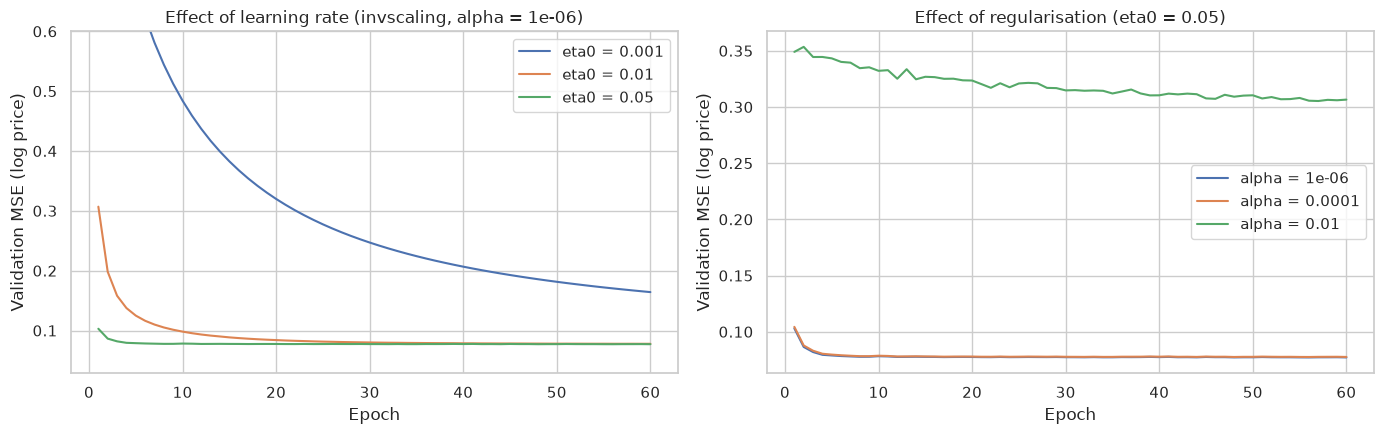

In [15]:
best_sgd = sgd_table.iloc[0]
print("Best SGD setting:", best_sgd[["schedule", "eta0", "alpha", "best epoch"]].to_dict())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for eta0 in [0.001, 0.01, 0.05]:
    hist = curves[(best_sgd["schedule"], eta0, best_sgd["alpha"])]
    axes[0].plot(range(1, len(hist) + 1), hist, label=f"eta0 = {eta0}")
axes[0].set(title=f"Effect of learning rate ({best_sgd['schedule']}, alpha = {best_sgd['alpha']:g})",
            xlabel="Epoch", ylabel="Validation MSE (log price)")
axes[0].set_ylim(top=min(0.6, axes[0].get_ylim()[1]))
axes[0].legend()
for alpha in [1e-6, 1e-4, 1e-2]:
    hist = curves[(best_sgd["schedule"], best_sgd["eta0"], alpha)]
    axes[1].plot(range(1, len(hist) + 1), hist, label=f"alpha = {alpha:g}")
axes[1].set(title=f"Effect of regularisation (eta0 = {best_sgd['eta0']})", xlabel="Epoch", ylabel="Validation MSE (log price)")
axes[1].set_ylim(top=min(0.6, axes[1].get_ylim()[1]))
axes[1].legend()
plt.tight_layout()
plt.show()

**What tuning showed.**

* **Learning rate.** With `eta0 = 0.001` and the `invscaling` schedule, the steps shrink so fast that after 60 epochs the validation MSE is still about 0.16, more than twice the best result. `eta0 = 0.05` reaches its lowest error within a few epochs. With a `constant` schedule, `eta0 = 0.05` is too big: the error stops improving after about 34 epochs and then gets worse (from 0.081 to 0.093), because the steps keep jumping around the minimum.
* **Regularisation.** `alpha = 0.01` pushes the weights too close to zero and the validation MSE stays above 0.26. `alpha = 0.000001` and `0.0001` give almost the same result (about 0.077 to 0.078). The model needs very little penalty: with about 122,000 rows and 177 columns it does not overfit.
* **Epochs.** The best setting (`invscaling`, `eta0 = 0.05`, `alpha = 0.000001`) is best at epoch 56, but most of the gain happens in the first 10 epochs.

### Final SGD model and its loss curve

I retrain the best setting on the full training set for the chosen number of epochs, and record train and test MSE after every epoch.

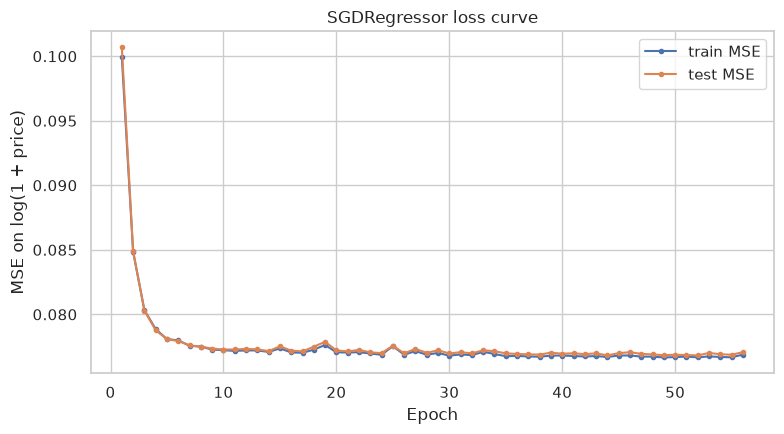

Epoch 1: train 0.1000, test 0.1007  |  epoch 56: train 0.0769, test 0.0771


In [16]:
SGD_EPOCHS = int(best_sgd["best epoch"])
sgd_pre_full = linear_preprocessor().fit(X_train)
A_train, A_test = sgd_pre_full.transform(X_train).tocsr(), sgd_pre_full.transform(X_test).tocsr()
sgd_model, sgd_train_hist, sgd_test_hist = run_sgd(
    best_sgd["eta0"], best_sgd["alpha"], best_sgd["schedule"], SGD_EPOCHS,
    A_train, y_train.to_numpy(), A_test, y_test.to_numpy())
sgd_pipe = Pipeline([("preprocess", sgd_pre_full), ("model", sgd_model)])

plt.figure(figsize=(8, 4.5))
epochs_axis = range(1, SGD_EPOCHS + 1)
plt.plot(epochs_axis, sgd_train_hist, marker="o", markersize=3, label="train MSE")
plt.plot(epochs_axis, sgd_test_hist, marker="o", markersize=3, label="test MSE")
plt.title("SGDRegressor loss curve")
plt.xlabel("Epoch")
plt.ylabel("MSE on log(1 + price)")
plt.legend()
plt.tight_layout()
plt.show()
print(f"Epoch 1: train {sgd_train_hist[0]:.4f}, test {sgd_test_hist[0]:.4f}  |  "
      f"epoch {SGD_EPOCHS}: train {sgd_train_hist[-1]:.4f}, test {sgd_test_hist[-1]:.4f}")

The loss falls fast in the first 5 epochs (from about 0.10 to 0.078) and then stays flat. The train and test curves stay close together (0.0769 and 0.0771 at the end), so the model is not overfitting. The flat part tells me that more epochs will not help: the limit is the straight line form of the model, not the training time.

## 7. Model 2: linear regression, closed form (`LinearRegression`)

The same one hot inputs, but the weights are found in one step with least squares instead of gradient descent. It shows how close SGD gets to the exact linear solution.

In [17]:
lin_pipe = Pipeline([("preprocess", linear_preprocessor()), ("model", LinearRegression())])
lin_pipe.fit(X_train, y_train)
pd.DataFrame([scores("LinearRegression", lin_pipe, X_train, y_train, X_test, y_test)])

,model,train MSE (log),test MSE (log),test R2,test RMSE (RWF),test MAPE
0,LinearRegression,0.076389,0.076647,0.934616,2696.297841,0.214088


## 8. Model 3: decision tree (`DecisionTreeRegressor`)

I tune `max_depth` (how many questions the tree may ask) and `min_samples_leaf` (the smallest group allowed at the end of a branch) on the validation set.

In [18]:
tree_rows = []
for depth in [10, 20, 30, None]:
    for leaf in [1, 3, 10]:
        m = Pipeline([("preprocess", tree_preprocessor()),
                      ("model", DecisionTreeRegressor(max_depth=depth, min_samples_leaf=leaf, random_state=RANDOM_STATE))])
        m.fit(X_tr, y_tr)
        tree_rows.append({"max_depth": depth if depth else "None", "min_samples_leaf": leaf,
                          "train MSE": mse(y_tr, m.predict(X_tr)), "validation MSE": mse(y_val, m.predict(X_val))})
tree_table = pd.DataFrame(tree_rows).sort_values("validation MSE").reset_index(drop=True)
tree_table

,max_depth,min_samples_leaf,train MSE,validation MSE
0,None,3,1.155307e-02,0.031707
1,30,3,1.155798e-02,0.031723
2,20,3,1.736272e-02,0.033809
3,30,10,2.583755e-02,0.034820
4,None,10,2.583755e-02,0.034820
5,20,10,2.784294e-02,0.036214
6,20,1,1.086654e-02,0.037598
7,30,1,8.457919e-05,0.038413
8,None,1,4.827306e-32,0.038463
9,10,10,8.075609e-02,0.081278


In [19]:
best_tree = tree_table.iloc[0]
depth = None if best_tree["max_depth"] == "None" else int(best_tree["max_depth"])
tree_pipe = Pipeline([("preprocess", tree_preprocessor()),
                      ("model", DecisionTreeRegressor(max_depth=depth, min_samples_leaf=int(best_tree["min_samples_leaf"]),
                                                      random_state=RANDOM_STATE))])
tree_pipe.fit(X_train, y_train)
print("Chosen:", {"max_depth": depth, "min_samples_leaf": int(best_tree["min_samples_leaf"])})
pd.DataFrame([scores("DecisionTree", tree_pipe, X_train, y_train, X_test, y_test)])

Chosen: {'max_depth': None, 'min_samples_leaf': 3}


,model,train MSE (log),test MSE (log),test R2,test RMSE (RWF),test MAPE
0,DecisionTree,0.011154,0.030131,0.974297,1151.323485,0.114056


A depth of 10 is too shallow (validation MSE about 0.081, no better than the linear models). With no minimum leaf size, the tree learns the training rows perfectly (train MSE close to 0) but the validation MSE gets worse (0.038), which is overfitting. Leaves of at least 3 rows give the best balance (validation MSE 0.0317). With that leaf size, a depth limit of 30 gives the same result as no limit, so the leaf size is what controls overfitting here. On the test set the tree reaches an MSE of 0.0301, already much better than both linear models, because it can learn a different price level for each product, market and year.

## 9. Model 4: random forest (`RandomForestRegressor`)

I tune `n_estimators` (number of trees), `min_samples_leaf` and `max_features` (share of inputs each split may look at). I also measure the saved file size, because the model must run on a free Render instance with 512 MB of memory. When I first deployed a 23 MB forest, the API used about 340 MB of memory right after starting and about 440 MB while retraining (the old and the new forest are both in memory for the comparison). That is too close to the limit, so a forest above **15 MB on disk** is not allowed to win, even if it is slightly more accurate.

In [20]:
def saved_size_mb(model):
    buffer = io.BytesIO()
    joblib.dump(model, buffer, compress=3)
    return buffer.tell() / 1e6


MAX_MODEL_MB = 15
forest_rows = []
for n_trees in [30, 50, 100]:
    for leaf in [3, 5, 10]:
        for max_feat in [1.0, 0.6]:
            m = Pipeline([("preprocess", tree_preprocessor()),
                          ("model", RandomForestRegressor(n_estimators=n_trees, min_samples_leaf=leaf, max_features=max_feat,
                                                          n_jobs=-1, random_state=RANDOM_STATE))])
            m.fit(X_tr, y_tr)
            forest_rows.append({"n_estimators": n_trees, "min_samples_leaf": leaf, "max_features": max_feat,
                                "train MSE": mse(y_tr, m.predict(X_tr)), "validation MSE": mse(y_val, m.predict(X_val)),
                                "file size MB": saved_size_mb(m)})
forest_table = pd.DataFrame(forest_rows).sort_values("validation MSE").reset_index(drop=True)
forest_table["fits limit"] = forest_table["file size MB"] <= MAX_MODEL_MB
forest_table

,n_estimators,min_samples_leaf,max_features,train MSE,validation MSE,file size MB,fits limit
0,100,3,1.0,0.012648,0.025282,77.271671,False
1,50,3,1.0,0.012752,0.025442,38.635265,False
2,30,3,1.0,0.012874,0.025612,23.180079,False
3,100,5,1.0,0.018094,0.027580,46.209499,False
4,50,5,1.0,0.018196,0.027708,23.107733,False
5,30,5,1.0,0.018308,0.027804,13.867297,True
6,100,3,0.6,0.016698,0.030713,74.666283,False
7,50,3,0.6,0.016871,0.030880,37.324917,False
8,30,3,0.6,0.017292,0.031571,22.414869,False
9,100,10,1.0,0.026273,0.032767,23.170341,False


In [21]:
best_forest = forest_table[forest_table["fits limit"]].iloc[0]
forest_params = {"n_estimators": int(best_forest["n_estimators"]), "min_samples_leaf": int(best_forest["min_samples_leaf"]),
                 "max_features": float(best_forest["max_features"])}
forest_pipe = Pipeline([("preprocess", tree_preprocessor()),
                        ("model", RandomForestRegressor(**forest_params, n_jobs=-1, random_state=RANDOM_STATE))])
forest_pipe.fit(X_train, y_train)
print("Chosen:", forest_params)
pd.DataFrame([scores("RandomForest", forest_pipe, X_train, y_train, X_test, y_test)])

Chosen: {'n_estimators': 30, 'min_samples_leaf': 5, 'max_features': 1.0}


,model,train MSE (log),test MSE (log),test R2,test RMSE (RWF),test MAPE
0,RandomForest,0.017456,0.026549,0.977352,1547.146458,0.111711


More trees and smaller leaves lower the error, but the file size grows fast. 100 trees with leaves of 3 rows reach the lowest validation MSE (0.0253) but weigh 77 MB. The number of trees matters less than I expected: with leaves of 5 rows, going from 30 to 100 trees only moves the validation MSE from 0.0278 to 0.0276, while the file gets more than three times bigger. Under my 15 MB limit, the best setting is 30 trees, leaves of at least 5 rows and all inputs at each split (validation MSE 0.0278, 14 MB). Using only 60% of the inputs at each split made things worse: with only five inputs, many splits then cannot see `commodity`, the input that matters most.

## 10. Comparison of the four models

All four models are scored on the same test set with MSE on the log price. I also show R², the error in RWF and the mean absolute percentage error (MAPE), which is the easiest number to explain to a farmer.

In [22]:
models = {"SGDRegressor": sgd_pipe, "LinearRegression": lin_pipe, "DecisionTree": tree_pipe, "RandomForest": forest_pipe}
comparison = pd.DataFrame([scores(name, m, X_train, y_train, X_test, y_test) for name, m in models.items()])
baseline_row = {"model": "Baseline (average)", "train MSE (log)": mse(y_train, np.full(len(y_train), baseline_value)),
                "test MSE (log)": baseline_mse, "test R2": 0.0,
                "test RMSE (RWF)": float(np.sqrt(mean_squared_error(np.expm1(y_test), np.full(len(y_test), np.expm1(baseline_value))))),
                "test MAPE": mean_absolute_percentage_error(np.expm1(y_test), np.full(len(y_test), np.expm1(baseline_value)))}
comparison = pd.concat([comparison, pd.DataFrame([baseline_row])], ignore_index=True)
comparison = comparison.sort_values("test MSE (log)").reset_index(drop=True)
shown = comparison.copy()
shown["test RMSE (RWF)"] = shown["test RMSE (RWF)"].round(0)
shown["test MAPE"] = (shown["test MAPE"] * 100).round(1).astype(str) + "%"
shown.round({"train MSE (log)": 4, "test MSE (log)": 4, "test R2": 3})

,model,train MSE (log),test MSE (log),test R2,test RMSE (RWF),test MAPE
0,RandomForest,0.0175,0.0265,0.977,1547.0,11.2%
1,DecisionTree,0.0112,0.0301,0.974,1151.0,11.4%
2,LinearRegression,0.0764,0.0766,0.935,2696.0,21.4%
3,SGDRegressor,0.0769,0.0771,0.934,2814.0,21.4%
4,Baseline (average),1.1909,1.1723,0.000,9594.0,94.5%


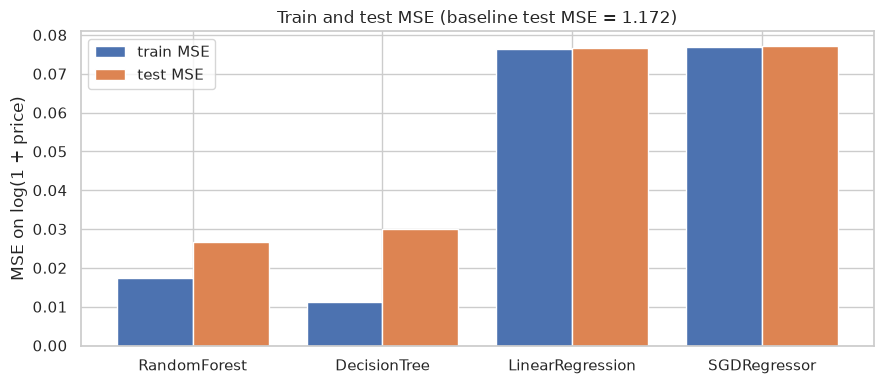

In [23]:
plot_df = comparison[comparison["model"] != "Baseline (average)"]
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(plot_df))
ax.bar(x - 0.2, plot_df["train MSE (log)"], width=0.4, label="train MSE")
ax.bar(x + 0.2, plot_df["test MSE (log)"], width=0.4, label="test MSE")
ax.set_xticks(x, plot_df["model"])
ax.set_ylabel("MSE on log(1 + price)")
ax.set_title(f"Train and test MSE (baseline test MSE = {baseline_mse:.3f})")
ax.legend()
plt.tight_layout()
plt.show()

In [24]:
best_name = comparison.loc[comparison["model"] != "Baseline (average)"].iloc[0]["model"]
best_model = models[best_name]
best_scores = comparison.set_index("model").loc[best_name]

# Deployment rule: the saved model must clearly beat the "always predict the average" baseline.
MIN_R2 = 0.80
MAX_MSE_RATIO = 0.50
passes = (best_scores["test R2"] >= MIN_R2) and (best_scores["test MSE (log)"] <= MAX_MSE_RATIO * baseline_mse)
print(f"Best model (lowest test MSE): {best_name}")
print(f"Test MSE {best_scores['test MSE (log)']:.4f} vs baseline {baseline_mse:.4f} "
      f"({best_scores['test MSE (log)'] / baseline_mse:.1%} of baseline), R2 = {best_scores['test R2']:.3f}")
print("Passes the deployment rule (R2 >= 0.80 and MSE <= 50% of baseline):", passes)

Best model (lowest test MSE): RandomForest
Test MSE 0.0265 vs baseline 1.1723 (2.3% of baseline), R2 = 0.977
Passes the deployment rule (R2 >= 0.80 and MSE <= 50% of baseline): True


**Best model: the random forest.** It has the lowest test MSE (0.0265 on the log price, R² 0.977). In plain terms, its typical error is about 11% of the real price (MAPE 11.2%). The decision tree is close behind (0.0301), and the two linear models are clearly weaker (0.0766 for `LinearRegression` and 0.0771 for SGD).

**How the dataset explains this order.** The price depends on the product, the market and the year together, and each crop has its own trend and harvest cycle (Section 3). A linear model adds one fixed effect per product, per market and per year, so it cannot learn that beans rose faster than potatoes, or that potatoes peak in October while maize peaks in November and December. Trees split on the product first and then on time and place, so they learn these combinations. The forest averages 30 trees trained on different samples of the rows, which smooths out the mistakes of a single tree, so it beats the single tree on the test set even though the single tree fits the training rows better. SGD ends almost exactly where the closed form `LinearRegression` is, which shows that gradient descent found the least squares solution.

**Deployment rule.** I only deploy a model that clearly beats the baseline that always predicts the average price: R² of at least 0.80 and a test MSE of at most 50% of the baseline MSE. The random forest's MSE is 2.3% of the baseline (0.0265 against 1.1723), so it passes. The same rule protects the `/retrain` endpoint: a retrained model that fails it, or that is worse than the current model, is not used.

## 11. Scatter plot before and after fitting a line

The heatmap showed that `year` is the numeric input most linked to the log price. Below is the scatter of year against log price, then the same scatter with a one feature linear regression line. This line is fitted only for this plot.

Numeric input most correlated with log price: year


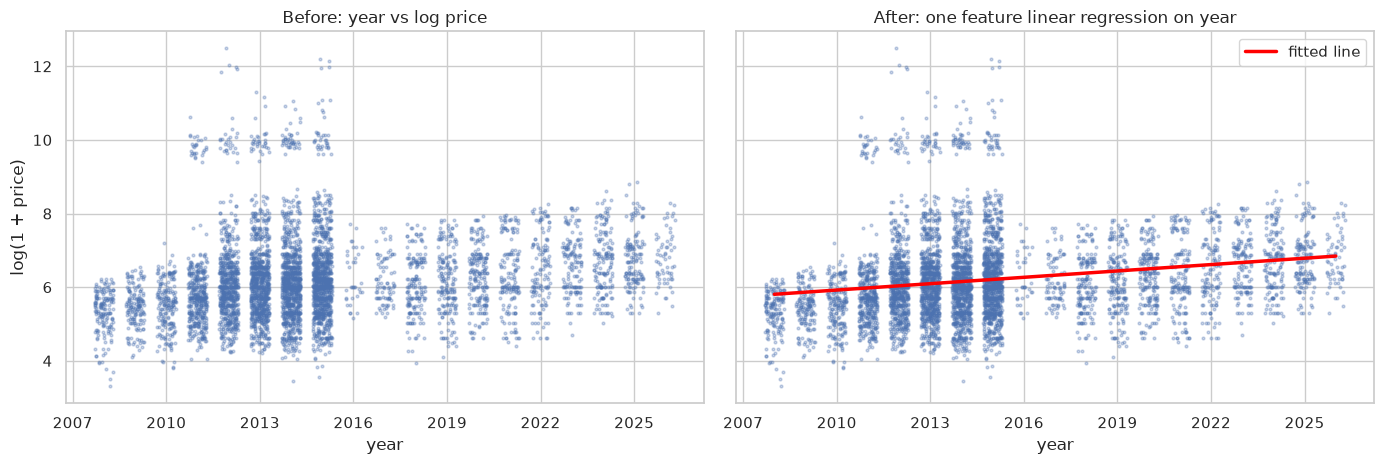

Slope: 0.0576 log units per year, about 5.9% higher prices per year on average


In [25]:
numeric_inputs = ["year", "month", "latitude", "longitude"]
strongest = data[numeric_inputs + ["log_price"]].corr()["log_price"].drop("log_price").abs().idxmax()
print("Numeric input most correlated with log price:", strongest)

train_idx = X_train.index
sample = data.loc[train_idx].sample(6000, random_state=RANDOM_STATE)
jitter = np.random.default_rng(RANDOM_STATE).uniform(-0.3, 0.3, len(sample))

one_feature = LinearRegression().fit(data.loc[train_idx, [strongest]], data.loc[train_idx, "log_price"])
line_x = np.linspace(data[strongest].min(), data[strongest].max(), 100)
line_y = one_feature.predict(pd.DataFrame({strongest: line_x}))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
axes[0].scatter(sample[strongest] + jitter, sample["log_price"], s=4, alpha=0.3)
axes[0].set(title=f"Before: {strongest} vs log price", xlabel=strongest, ylabel="log(1 + price)")
axes[1].scatter(sample[strongest] + jitter, sample["log_price"], s=4, alpha=0.3)
axes[1].plot(line_x, line_y, color="red", linewidth=2.5, label="fitted line")
axes[1].set(title=f"After: one feature linear regression on {strongest}", xlabel=strongest)
axes[1].legend()
for ax in axes:
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout()
plt.show()
slope = one_feature.coef_[0]
print(f"Slope: {slope:.4f} log units per year, about {np.expm1(slope):.1%} higher prices per year on average")

Year alone is a weak predictor (correlation 0.22). At each year the points spread from about 4 to 10 on the log scale, because products differ much more than years do. The groups of points near 10 are live animals. The red line still shows the general trend: prices rise by about 5.9% per year on average, which matches the rise of staple prices in Section 3. This is why the full model needs `commodity` and not only time.

## 12. Which inputs matter most

The random forest uses the five inputs directly (ordinal codes), so its importance scores show how much each input reduces the error.

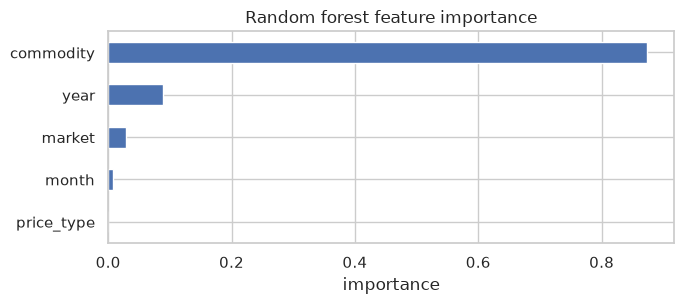

commodity     0.874
year          0.089
market        0.029
month         0.008
price_type    0.000


In [26]:
importance = pd.Series(forest_pipe.named_steps["model"].feature_importances_, index=NUMERIC + CATEGORICAL).sort_values()
importance.plot(kind="barh", figsize=(7, 3.2), color="#4C72B0", title="Random forest feature importance")
plt.xlabel("importance")
plt.tight_layout()
plt.show()
print(importance.sort_values(ascending=False).round(3).to_string())

`commodity` carries most of the importance (0.874), then `year` (0.089), `market` (0.029) and `month` (0.008). This matches the correlation ratio table in Section 3. `price_type` scores almost zero because wholesale prices exist only for maize, rice and beans (about 500 rows, less than 1% of the data). I still keep it, because a cooperative that sells in bulk needs to ask for the wholesale price, and the API warns when a product has no wholesale history.

## 13. Save the best model with its preprocessing

The saved file holds the full scikit-learn `Pipeline` (imputers, scaler, encoder and model), plus the lists of valid markets and products that the API uses to check inputs. I also save the training and test rows, so that `/retrain` can refit on the original data plus the new rows, and check the new model on the same test rows before using it.

In [27]:
location = data.groupby("market")[["admin2", "admin1"]].first()
units = data.groupby("commodity")["unit"].first()
pair_counts = data.groupby(["market", "commodity"]).size()

bundle = {
    "model": best_model,
    "model_name": best_name,
    "version": 1,
    "trained_at": datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC"),
    "target_transform": "log1p",
    "features": FEATURES,
    "numeric_features": NUMERIC,
    "categorical_features": CATEGORICAL,
    "allowed_values": {
        "market": sorted(data["market"].unique().tolist()),
        "commodity": sorted(data["commodity"].unique().tolist()),
        "price_type": sorted(data["price_type"].unique().tolist()),
    },
    "year_range": [int(data["year"].min()), int(data["year"].max())],
    "commodity_units": units.to_dict(),
    "market_locations": {m: {"district": r["admin2"], "province": r["admin1"]} for m, r in location.iterrows()},
    "pair_counts": {f"{m}|{c}": int(n) for (m, c), n in pair_counts.items()},
    "outlier_factor": OUTLIER_FACTOR,
    "metrics": {
        "test_mse_log": float(best_scores["test MSE (log)"]),
        "test_r2": float(best_scores["test R2"]),
        "test_rmse_rwf": float(best_scores["test RMSE (RWF)"]),
        "test_mape": float(best_scores["test MAPE"]),
        "baseline_test_mse_log": float(baseline_mse),
    },
    "deployment_rule": {"min_r2": MIN_R2, "max_mse_ratio_to_baseline": MAX_MSE_RATIO},
}
joblib.dump(bundle, API_DIR / "best_model.pkl", compress=3)

keep = FEATURES + [TARGET]
data.loc[X_train.index, keep].to_csv(API_DIR / "data" / "train.csv.gz", index=False)
data.loc[X_test.index, keep].to_csv(API_DIR / "data" / "test.csv.gz", index=False)
print("Saved", API_DIR / "best_model.pkl", f"({(API_DIR / 'best_model.pkl').stat().st_size / 1e6:.1f} MB)")
print("Saved training rows:", len(X_train), "| test rows:", len(X_test))

Saved ../API/best_model.pkl (16.3 MB)
Saved training rows: 122904 | test rows: 30726


## 14. Load the saved model and predict one row of the test set

The function below is the same one the API uses in `API/price_model.py`.

In [28]:
def predict_price(row, model_path=API_DIR / "best_model.pkl"):
    # Loads the saved bundle and returns the predicted price in RWF for one input row.
    saved = joblib.load(model_path)
    frame = pd.DataFrame([row])[saved["features"]]
    log_prediction = saved["model"].predict(frame)[0]
    return float(np.expm1(log_prediction))


test_row = X_test.iloc[0].to_dict()
actual = float(np.expm1(y_test.iloc[0]))
predicted = predict_price(test_row)
unit = bundle["commodity_units"][test_row["commodity"]]
print("Input row:", test_row)
print(f"Predicted price: {predicted:,.0f} RWF per {unit}")
print(f"Actual price:    {actual:,.0f} RWF per {unit}  (error {abs(predicted - actual) / actual:.1%})")

Input row: {'year': 2012, 'month': 10, 'market': 'Birambo', 'commodity': 'Avocados', 'price_type': 'Retail'}
Predicted price: 134 RWF per Unit
Actual price:    102 RWF per Unit  (error 32.5%)


In [29]:
examples = X_test.sample(5, random_state=7)
check = examples.copy()
check["actual RWF"] = np.expm1(y_test.loc[examples.index]).round(0)
check["predicted RWF"] = [round(predict_price(r), 0) for r in examples.to_dict("records")]
check["error"] = ((check["predicted RWF"] - check["actual RWF"]).abs() / check["actual RWF"]).map("{:.1%}".format)
check

,year,month,market,commodity,price_type,actual RWF,predicted RWF,error
6087,2009,6,Mahoko,Cassava flour,Retail,271.0,278.0,2.6%
38767,2012,9,Musha,Bananas,Retail,150.0,112.0,25.3%
66687,2013,12,Birambo,Carrots,Retail,290.0,281.0,3.1%
116264,2015,11,Kibuye (Karongi),Peas (fresh),Retail,1000.0,1072.0,7.2%
97290,2015,3,Butare,Meat (beef),Retail,1711.0,1784.0,4.3%


## 15. Summary

* **Data:** 153,630 cleaned monthly prices from 109 markets and 64 products, January 2008 to May 2026. June to August 2026 (895 rows) are kept in `API/sample_new_data.csv` to test retraining.
* **Best model:** random forest, test MSE 0.0265 on the log price, R² 0.977, typical error about 11% of the price. Saved with its preprocessing in `API/best_model.pkl`.
* **Is the loss low for this use case?** Yes. The baseline MSE is 1.17, so the model removes about 98% of it. An 11% typical error means that for beans at 800 RWF per kg, the estimate is usually within about 90 RWF. That is enough to tell a fair offer from a very low one. It is weaker for product and market pairs with few records, so the API returns how many past records exist for the pair.
* **How to lower it further:** add rainfall and harvest season data (weather is part of my mission), add last month's price for the same product and market as an input, and try gradient boosting, which can be accurate while staying small on disk.
* **Limit:** trees cannot go beyond the last year they saw. For 2027 the model returns prices close to the 2026 level, so the API accepts years only up to 2027 and the app shows the result as an estimate.